In [1]:
from IPython.display import display, clear_output
import os
import sourcedefender
import numpy as np
import torch
import sys
import argparse
import time
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from tqdm import tqdm
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split, dataset, Subset
import pandas as pd
import argparse
from mpl_toolkits.mplot3d import Axes3D
import gc
from datetime import datetime

sys.path.append("../../../")
sys.path.append("../")
sys.path.append("./")

from lib.util import MHPI, UnitGaussianNormalizer
from lib.utilities3 import prepare_dataset, upscale_tensor, calculate_errors, check_if_from_ddp, adjust_state_dict, plot_log_loss, NonLocalMeansSmoothing, calculate_relative_errors
from lib.utiltools import loss_live_plot, GaussianRandomFieldGenerator, generate_batch_parameters, AutomaticWeightedLoss
from lib.DerivativeComputer import batchJacobian_AD_Dist
from lib.hellper import *
from lib.helper import LargeHydrologyDataset
from lib.helper import get_checkpoint_path
from lib.evaluation import evaluate_flood_metrics, inundation_extent_timeseries, plot_detection_skill_time, plot_inundation_extent_time, plot_ever_inundation_confusion

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f'Device: {device}\n')

# Dataset and case configuration
SAVED_MODEL_PATH = '../../../experiments/Hurricane_Matthew/saved_models'
# This creates a 'pointer' to the data on disk without filling up your RAM
case = 'Hurricane_Matthew'
operator_type = 'FNO'



Device: cuda:0



# Loading Dataset

In [2]:
eval_size = 150
batch_size = 2
T_Total = 89

T_in = 1
T_out = T_Total - T_in

Nx = 164 * 2
Ny = 164

In [6]:
# --- 1. Load Magnifier Model ---
train_size = 300
tag_mag = 'test_mag_residual_model5_Deep_stage2_N1'


path_mag = '../../../experiments/saved_model/flooding_best_model.pth'
checkpoint_mag = torch.load(path_mag, map_location=device, weights_only=False)
mode_mag = 'test_mag_residual_model5_Deep_stage2_N1'
if 'stage2' in tag_mag:
    plot_log_loss(checkpoint_mag["loss_df_magnifier"], mode=mode_mag + '_Magnifier_Model' + f' (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)
else:
    plot_log_loss(checkpoint_mag["loss_df_main"], mode=mode_mag + '_Global_Model' + f'  (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)

loading dataset

In [12]:
from pathlib import Path

data_dir = Path("../../../datasets/1_flooding")

topo_path = data_dir / "flooding_bed_topo.pt"
a_path    = data_dir / "flooding_input.pt"
u_path    = data_dir / "flooding_solution.pt"

# full_dataset = LargeHydrologyDataset(a_path, u_path)
full_dataset = LargeHydrologyDataset(a_path, u_path, mask=False, 
                                     csv_path=os.path.join('../../../',  checkpoint_mag['config_arg']['data_mask']['csv_path']), 
                                     Lx=checkpoint_mag['config_arg']['data_mask']['L_x'], Ly=checkpoint_mag['config_arg']['data_mask']['L_y'])

# 2. Split with a fixed generator for reproducibility
n = len(full_dataset)

# Make deterministic indices
g = torch.Generator().manual_seed(42)
perm = torch.randperm(n, generator=g).tolist()
test_idx  = perm[train_size + eval_size:]
test_dataset = Subset(full_dataset, test_idx)

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Loading Trained Models

In [13]:
from models.fno3d_encoder import FNO3d
from models.magnifier5 import FiLMLightMagnifier as magnifier

# --- 1. Load Global Model ---
model_global = FNO3d(
    T_in=T_in, T_out=T_out,
    modes_x=checkpoint_mag['config']['Mode1_G'], 
    modes_y=checkpoint_mag['config']['Mode2_G'], 
    modes_t=checkpoint_mag['config']['Mode3_G'],
    width=checkpoint_mag['config']['width_FNO'],
    
    encoder_kernel_size_x=82,
    encoder_kernel_size_y=41,
    encoder_num_layers=4
)

is_DDP_glb = check_if_from_ddp(checkpoint_mag)
  
if is_DDP_glb:   
    adjusted_state_dict = adjust_state_dict(checkpoint_mag['model_state_dict'], model_global)
    model_global.load_state_dict(adjusted_state_dict)
else:
    model_global.load_state_dict(checkpoint_mag['model_state_dict'])

model_global = model_global.to(device)


# --- 2. Load Magnifier Model ---
model_magnifier = magnifier(width=64).to(device)

is_DDP_mag = check_if_from_ddp(checkpoint_mag)

state_dict_mag = checkpoint_mag['magnifier_state_dict'] 

if is_DDP_mag:   
    state_dict_mag = adjust_state_dict(state_dict_mag, model_magnifier)

model_magnifier.load_state_dict(state_dict_mag)


<All keys matched successfully>

# Generate coarse-resolution depth predictions using the trained global model.

In [15]:
import time
import torch
from tqdm import tqdm
from lib.helper import coarsen_spatial_tensor

model_global.eval()

# ---- user control ----
MAX_SAMPLES = 50   # <- set this to how many samples you want

# ---- load topo once ----
topo = torch.load(topo_path, map_location="cpu").to(device)
bed_topo_all = torch.empty(0, device="cpu")
# ---- CPU buffers ----
forcing_all = torch.empty(0, device="cpu")
u0_all      = torch.empty(0, device="cpu")
u_true_all  = torch.empty(0, device="cpu")
u_pred_coarse_all  = torch.empty(0, device="cpu")

t_start = time.time()
num_collected = 0

with torch.no_grad():
    for _, batch_data in tqdm(enumerate(test_loader, 1), total=len(test_loader),
                              desc="Processing batches"):

        batch_data = [item.to(device, non_blocking=True) for item in batch_data]
        batch_forcing = batch_data[0][..., ::1]
        batch_sol     = batch_data[1][..., ::1]

        # batch_u0    = torch.ones_like(batch_sol[..., :T_in])
        batch_u0    = batch_sol[..., :T_in]

        batch_u_out = batch_sol[..., T_in:]

        bs = batch_u0.shape[0]

        # ---- trim batch if it would exceed MAX_SAMPLES ----
        remaining = MAX_SAMPLES - num_collected
        if remaining <= 0:
            break
        if bs > remaining:
            batch_forcing = batch_forcing[:remaining]
            batch_u0      = batch_u0[:remaining]
            batch_u_out   = batch_u_out[:remaining]
            bs = remaining

        batch_topo = topo.expand(bs, -1, -1)

        U_pred_batch = model_global(batch_forcing, batch_u0, batch_topo)
        U_pred_batch[U_pred_batch < 0.025] = 0
        # ---- move to CPU ----
        forcing_all = torch.cat((forcing_all, batch_forcing.cpu()), dim=0)
        u0_all      = torch.cat((u0_all, batch_u0.cpu()), dim=0)
        u_true_all  = torch.cat((u_true_all, batch_u_out.cpu()), dim=0)
        u_pred_coarse_all  = torch.cat((u_pred_coarse_all, U_pred_batch.cpu()), dim=0)
        bed_topo_all = torch.cat((bed_topo_all, batch_topo.cpu()), dim=0)
        num_collected += bs

        del batch_forcing, batch_sol, batch_u0, batch_u_out, batch_topo, U_pred_batch
        
u_pred_coarse_all[u_pred_coarse_all<0.025] = 0.0
u_true_all[u_true_all<0.025] = 0.0

t_end = time.time()
print(
    f"Processed {num_collected} samples in {t_end - t_start:.2f}s "
    f"({(t_end - t_start)/max(num_collected,1):.3f} s/sample)"
)

u_true_all_coarse = coarsen_spatial_tensor(u_true_all, N=4,  mode=checkpoint_mag['config_arg']['model']['coarsen_mode'])


Processing batches:   9%|▉         | 25/275 [00:24<04:08,  1.00it/s]


Processed 50 samples in 25.49s (0.510 s/sample)


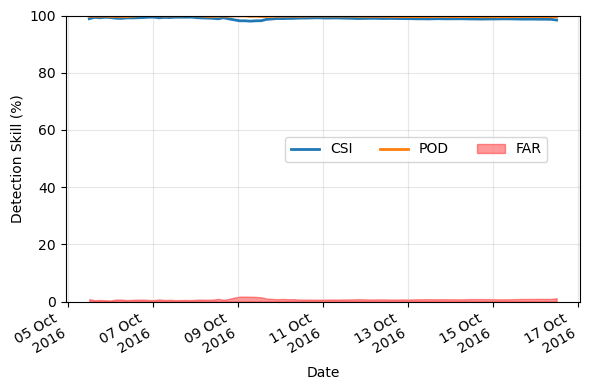

In [16]:
metrics_coarse = evaluate_flood_metrics(
    Depth_True=u_true_all_coarse,
    Depth_Pred=u_pred_coarse_all,
    wet_threshold=0.025,
    peak_percent=0.025
)



fig, ax = plot_detection_skill_time(
    metrics_coarse['dynamic'],
    start_datetime=datetime(2016, 10, 5, 12, 0, 0),
    end_datetime=datetime(2016, 10, 16, 12, 0, 0)
)

plt.show()


In [17]:
metrics_coarse['static']

{'relRMSE_mean': 0.02188866212964058,
 'relRMSE_std': 0.0053345756605267525,
 'NSE_mean': 0.9999495148658752,
 'NSE_std': 2.7697211407939903e-05,
 'relRMSE_shallow_mean': 0.18306133151054382,
 'relRMSE_shallow_std': 0.04498488828539848,
 'NSE_shallow_mean': 0.9977014064788818,
 'NSE_shallow_std': 0.0013383276527747512,
 'relRMSE_deep_mean': 0.004910006653517485,
 'relRMSE_deep_std': 0.0012678696075454354,
 'NSE_deep_mean': 0.9999229907989502,
 'NSE_deep_std': 4.580938184517436e-05,
 'POD_mean': 0.9971030354499817,
 'POD_std': 0.0011422267416492105,
 'FAR_mean': 0.00798308476805687,
 'FAR_std': 0.002668397966772318,
 'CSI_mean': 0.9891639947891235,
 'CSI_std': 0.0025097248144447803,
 'relPeakValErr_mean': -0.0002931772032752633,
 'relPeakValErr_std': 0.001881999196484685,
 'relPeakTimeErr1_mean': 0.0,
 'relPeakTimeErr1_std': 0.3499270975589752,
 'relPeakTimeErr2_mean': -0.00041184856672771275,
 'relPeakTimeErr2_std': 0.024378696456551552}

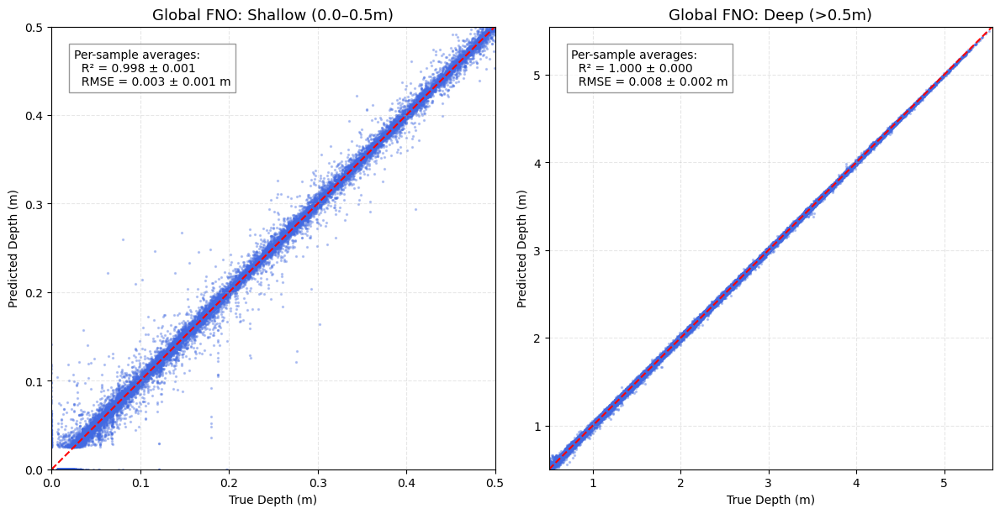

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

# ─── Data Setup: Focus on Coarse Row Only ────────────────────────────────────
# u_true_all_coarse: Ground Truth after 'area' coarsening
# u_pred_coarse_all: Raw FNO output before upscaling
u_true_c = u_true_all_coarse.detach().cpu().numpy()
u_pred_c = u_pred_coarse_all.detach().cpu().numpy()

# Dataset list reduced to just the Coarse Global Model
datasets = [(u_true_c, u_pred_c, "Global FNO (Coarse)")]

# Define depth ranges (m)
depth_ranges = [
    (0.0, 0.5, "Shallow (0.0–0.5m)"),
    (0.5, u_true_c.max(), "Deep (>0.5m)")
]

# Create 1 row x 2 cols plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Since there's only one row, axes will be a 1D array
for col_idx, (dmin, dmax, range_title) in enumerate(depth_ranges):
    ax = axes[col_idx]
    
    r2_list, rmse_list = [], []
    scatter_x, scatter_y = [], []
    
    for i in range(u_true_c.shape[0]):
        true_flat = u_true_c[i].ravel()
        pred_flat = u_pred_c[i].ravel()
        
        # Apply depth mask
        mask = (true_flat >= dmin) & (true_flat < dmax)
        if np.sum(mask) < 50: continue
            
        x_s, y_s = true_flat[mask], pred_flat[mask]
        
        r2_list.append(r2_score(x_s, y_s))
        rmse_list.append(np.sqrt(mean_squared_error(x_s, y_s)))
        
        # Subsampling for performance
        if len(x_s) > 5000:
            sel = np.random.choice(len(x_s), 5000, replace=False)
            scatter_x.extend(x_s[sel]); scatter_y.extend(y_s[sel])
        else:
            scatter_x.extend(x_s); scatter_y.extend(y_s)
    
    # Plotting
    ax.scatter(scatter_x, scatter_y, s=2, alpha=0.3, color='royalblue', rasterized=True)
    limit_max = dmax if np.isfinite(dmax) else max(scatter_x)
    ax.plot([dmin, limit_max], [dmin, limit_max], 'r--', lw=1.5, label='Ideal')
    
    ax.set_xlim(dmin, limit_max); ax.set_ylim(dmin, limit_max)
    ax.set_aspect('equal')
    
    metrics_text = (
        f"Per-sample averages:\n"
        f"  R² = {np.mean(r2_list):.3f} ± {np.std(r2_list):.3f}\n"
        f"  RMSE = {np.mean(rmse_list):.3f} ± {np.std(rmse_list):.3f} m"
    )
    ax.text(0.05, 0.95, metrics_text, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))
    
    ax.set_title(f"Global FNO: {range_title}", fontsize=13)
    ax.set_xlabel("True Depth (m)"); ax.set_ylabel("Predicted Depth (m)")
    ax.grid(True, ls='--', alpha=0.3)

plt.tight_layout()
plt.show()

Plot inundation confusion

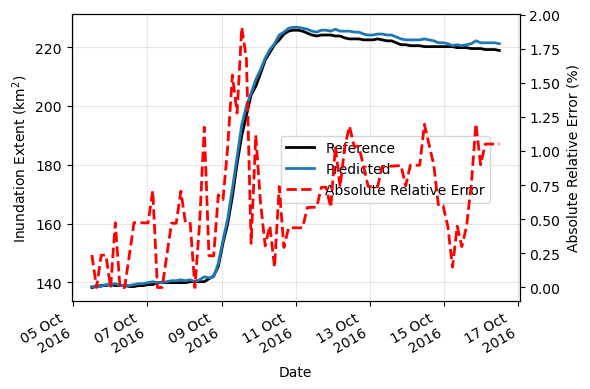

In [19]:
idx = 0
wet_threshold = 0.025

inundation_extent_coarse_pred = inundation_extent_timeseries(
    depth=u_pred_coarse_all,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
    wet_threshold=wet_threshold,
)


inundation_extent_coarse_true = inundation_extent_timeseries(
    depth=u_true_all_coarse,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
    wet_threshold=wet_threshold,
)


fig, ax1, ax2 = plot_inundation_extent_time(
    inundation_extent_coarse_true,
    inundation_extent_coarse_pred,
    idx=10,
    start_datetime=datetime(2016, 10, 5, 12, 0, 0),
    end_datetime=datetime(2016, 10, 16, 12, 0, 0)
)

plt.show()


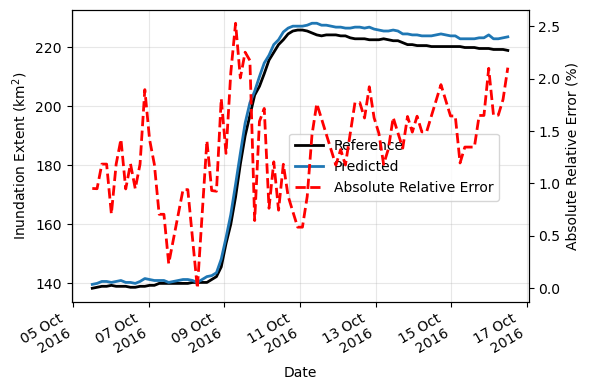

In [10]:
idx = 0
wet_threshold = 0.025

inundation_extent_coarse_pred = inundation_extent_timeseries(
    depth=u_pred_coarse_all,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
    wet_threshold=wet_threshold,
)


inundation_extent_coarse_true = inundation_extent_timeseries(
    depth=u_true_all_coarse,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
    wet_threshold=wet_threshold,
)


fig, ax1, ax2 = plot_inundation_extent_time(
    inundation_extent_coarse_true,
    inundation_extent_coarse_pred,
    idx=10,
    start_datetime=datetime(2016, 10, 5, 12, 0, 0),
    end_datetime=datetime(2016, 10, 16, 12, 0, 0)
)

plt.show()


(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Ever-inundation confusion (sample=20, th=0.025 m)'}, xlabel='x (km)', ylabel='y (km)'>)

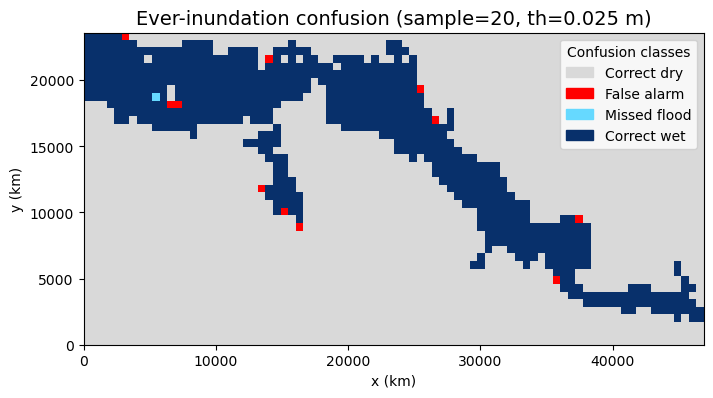

In [20]:
Ly=checkpoint_mag['config_arg']['data_mask']['L_x']
Lx=checkpoint_mag['config_arg']['data_mask']['L_y']
extent = [0, Lx, 0, Ly]

plot_ever_inundation_confusion(u_true_all_coarse, u_pred_coarse_all, sample_idx=20, inund_th=0.025, extent=extent)


(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Across-samples confusion (MODE per pixel, th=0.05 m)'}, xlabel='x (km)', ylabel='y (km)'>)

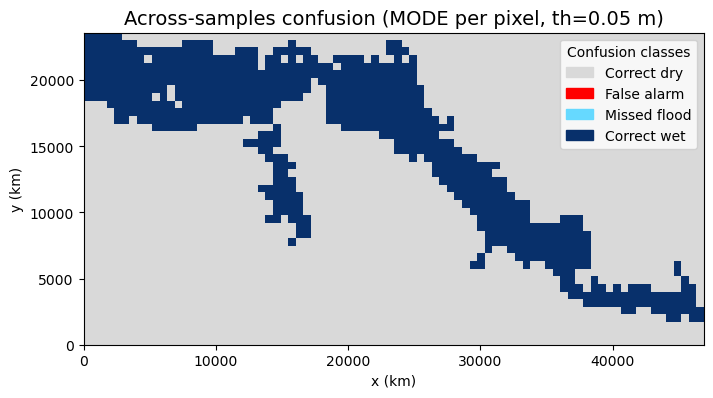

In [21]:
plot_ever_inundation_confusion(u_true_all_coarse, u_pred_coarse_all, inund_th=0.05, extent=extent)

In [13]:
import torch
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
from datetime import datetime, timedelta
import numpy as np

# ==========================================
# 1) Data Selection & Error Calculation (Coarse Only)
# ==========================================
sample_idx = 20 

# Extract Coarse Data [nx_c, ny_c, nt]
# Using the ::4 stride to match your temporal subsetting
u_true_c = u_true_all_coarse[sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[sample_idx].detach().cpu().numpy()
u_err_c  = np.abs(u_true_c - u_pred_c)

num_frames = u_true_c.shape[-1]

# ==========================================
# 2) Coordinate & Color Configuration
# ==========================================
start_date = datetime(2016, 10, 5, 12, 0, 0)
time_step_seconds = 3600
time_dates = [start_date + timedelta(seconds=i * time_step_seconds) for i in range(num_frames)]

# Color scales
vmin, vmax = 0.0, u_true_c.max() * 0.8
err_vmin, err_vmax = 0.0, 0.2  # Fixed scale for identifying spatial error clusters

# Physical extent logic for PSU state college area data
# X_range = 248417.934 - 201527.934
# Y_range = 3922540.192 - 3898940.192
extent = [0, 46890.0, 0, 23600.0]

# ==========================================
# 3) Figure Setup: 1 Row x 3 Columns
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

titles = ["True (Coarse)", "Pred (Coarse)", "Abs Error (Coarse)"]
ims = [None] * 3

# Initialize images
# .T aligns [nx, ny] with imshow's [y, x] requirement
ims[0] = axes[0].imshow(u_true_c[:, :, 0].T, extent=extent, origin="lower", cmap="terrain", vmin=vmin, vmax=vmax)
ims[1] = axes[1].imshow(u_pred_c[:, :, 0].T, extent=extent, origin="lower", cmap="terrain", vmin=vmin, vmax=vmax)
ims[2] = axes[2].imshow(u_err_c[:, :, 0].T,  extent=extent, origin="lower", cmap="magma", vmin=err_vmin, vmax=err_vmax)

for i in range(3):
    axes[i].set_title(titles[i], fontsize=14)
    axes[i].grid(True, linestyle="--", alpha=0.3)
    axes[i].set_xlabel("Easting (m)")

axes[0].set_ylabel("Northing (m)")

# Add colorbars
cbar_ax1 = fig.add_axes([0.15, 0.08, 0.35, 0.03])
fig.colorbar(ims[0], cax=cbar_ax1, label="Water Depth (m)", orientation="horizontal")

cbar_ax2 = fig.add_axes([0.65, 0.08, 0.20, 0.03])
fig.colorbar(ims[2], cax=cbar_ax2, label="Abs Error (m)", orientation="horizontal")

plt.subplots_adjust(bottom=0.22, wspace=0.15)

# ==========================================
# 4) Update Function
# ==========================================
def update(f_idx):
    current_dt = time_dates[f_idx]
    fig.suptitle(
        f"Global FNO Dynamics: Sample {sample_idx}\nTime: {current_dt.strftime('%Y-%m-%d %H:%M')}",
        fontsize=16, fontweight="bold"
    )
    
    ims[0].set_data(u_true_c[:, :, f_idx].T)
    ims[1].set_data(u_pred_c[:, :, f_idx].T)
    ims[2].set_data(u_err_c[:, :, f_idx].T)

    return ims

# ==========================================
# 5) Generate Animation
# ==========================================

ani = animation.FuncAnimation(fig, update, frames=range(num_frames), interval=200, blit=False)
plt.close(fig)
HTML(ani.to_jshtml())

# Apply the trained Magnifier for topography-aware upscaling.

In [22]:
from lib.helper import prepare_patch_input, BathtubReconstructor
import torch
import torch.nn.functional as F
from tqdm import tqdm

model_magnifier.eval()
DRY_THRESHOLD = 0.025
# ---- Configuration from Checkpoints ----
N = checkpoint_mag['config']['N_window']       # e.g., 5
f = checkpoint_mag['config']['f_upscale']      # e.g., 10
T_out = checkpoint_mag['config']['T_out']

# Global dimensions
num_samples, mx, my, _ = u_pred_coarse_all.shape
nx_fine, ny_fine = mx * f, my * f

# ---- Initialize Reconstructor for Inference ----
reconstructor = BathtubReconstructor(f=f, max_iters=20).to(device)

# ---- Buffers ----
u_upscaled_acc = torch.zeros((num_samples, nx_fine, ny_fine, T_out), device="cpu")
u_upscaled_cnt = torch.zeros((num_samples, nx_fine, ny_fine, T_out), device="cpu")

# ---- Global Normalization Constants ----
GLOBAL_TOPO_MIN = bed_topo_all.min()
GLOBAL_TOPO_MAX = bed_topo_all.max()
TOPO_RANGE = (GLOBAL_TOPO_MAX - GLOBAL_TOPO_MIN) + 1e-7

# ---- 1. Generate Global Bathtub Reconstruction ----
print("Generating Global Bathtub Baseline...")
with torch.no_grad():
    u_bt_global = reconstructor(u_pred_coarse_all.to(device), bed_topo_all.to(device))

# ---- 2. Padding Alignment ----
pad_size = N // 2

u_pad = F.pad(
    u_pred_coarse_all.permute(0, 3, 1, 2),
    (pad_size, pad_size, pad_size, pad_size),
    mode="replicate",
).permute(0, 2, 3, 1).to(device)

pad_size_f = pad_size * f

u_bt_pad = F.pad(
    u_bt_global.permute(0, 3, 1, 2),
    (pad_size_f, pad_size_f, pad_size_f, pad_size_f),
    mode="replicate",
).permute(0, 2, 3, 1).to(device)

topo_norm = (bed_topo_all.to(device) - GLOBAL_TOPO_MIN) / TOPO_RANGE
topo_pad = F.pad(
    topo_norm,
    (pad_size_f, pad_size_f, pad_size_f, pad_size_f),
    mode="replicate",
).to(device)

print(f"Starting Aligned Magnifier Upscaling for {num_samples} samples...")

center_start = (N // 2) * f
center_end = center_start + f

with torch.no_grad():
    step = 1
    for i_s in tqdm(range(0, mx, step), desc="Spatial X"):
        for j_s in range(0, my, step):

            # ---------------------------------------------------------
            # Gate ONLY by the CENTER coarse cell (the one we stitch)
            # ---------------------------------------------------------
            ic = i_s + (N // 2)
            jc = j_s + (N // 2)

            center_coarse_ts = u_pad[:, ic, jc, :]  # [nb, nt]
            center_is_wet = (center_coarse_ts.max(dim=-1).values >= DRY_THRESHOLD)  # [nb]

            # Fine indices for the stitched fxf block
            x_start, x_end = i_s * f, i_s * f + f
            y_start, y_end = j_s * f, j_s * f + f

            # ---------------------------------------------------------
            # If center is dry -> DO NOT use magnifier, FORCE ZERO
            # (acc stays 0; count increments so average is 0)
            # ---------------------------------------------------------

            if not center_is_wet.any():
                u_upscaled_cnt[:, x_start:x_end, y_start:y_end, :] += 1.0
                continue

            # move indices to CPU because u_upscaled_acc/cnt are on CPU
            wet_idx = torch.where(center_is_wet)[0].to("cpu")
            dry_idx = torch.where(~center_is_wet)[0].to("cpu")

            # Prepare patch input on GPU, then slice using GPU indices
            wet_idx_gpu = wet_idx.to(device)

            p_in = prepare_patch_input(u_pad, topo_pad, i_s, j_s, N, f, device, u_bathtub=u_bt_pad)
            p_in_wet = p_in[wet_idx_gpu]

            p_residual = model_magnifier(p_in_wet).squeeze(1)

            p_bt_patch = u_bt_pad[
                wet_idx_gpu,
                i_s*f : i_s*f + N*f,
                j_s*f : j_s*f + N*f,
                :
            ]

            p_out = p_bt_patch + p_residual
            p_out[p_out < DRY_THRESHOLD] = 0.0

            p_center = p_out[:, center_start:center_end, center_start:center_end, :].cpu()

            # CPU indexing with CPU indices ✅
            u_upscaled_acc[wet_idx, x_start:x_end, y_start:y_end, :] += p_center
            u_upscaled_cnt[wet_idx, x_start:x_end, y_start:y_end, :] += 1.0

            # dry -> force zero (count only)
            if dry_idx.numel() > 0:
                u_upscaled_cnt[dry_idx, x_start:x_end, y_start:y_end, :] += 1.0


# ---- Final Averaging ----
mask = u_upscaled_cnt > 0
u_upscaled_final = torch.zeros_like(u_upscaled_acc)
u_upscaled_final[mask] = u_upscaled_acc[mask] / u_upscaled_cnt[mask]

print(f"Upscaling Complete. Final Shape: {u_upscaled_final.shape}")


Generating Global Bathtub Baseline...
Starting Aligned Magnifier Upscaling for 50 samples...


Spatial X: 100%|██████████| 82/82 [00:21<00:00,  3.77it/s]


Upscaling Complete. Final Shape: torch.Size([50, 328, 164, 88])


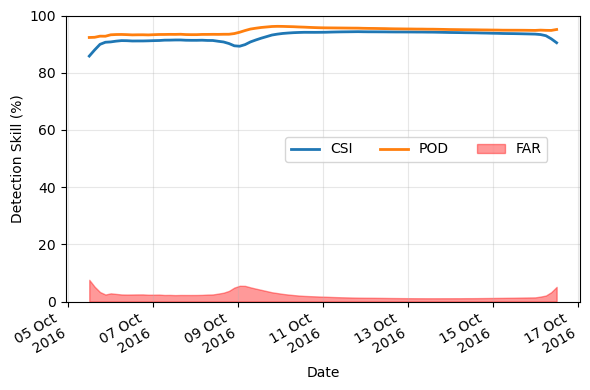

In [23]:
metrics_fine = evaluate_flood_metrics(
    Depth_True=u_true_all,
    Depth_Pred=u_upscaled_final,
    wet_threshold=0.025,
    peak_percent=0.025
)


fig, ax = plot_detection_skill_time(
    metrics_fine['dynamic'],
    start_datetime=datetime(2016, 10, 5, 12, 0, 0),
    end_datetime=datetime(2016, 10, 16, 12, 0, 0)
)

plt.show()


In [24]:
metrics_fine['static']

{'relRMSE_mean': 0.331537127494812,
 'relRMSE_std': 0.012300114147365093,
 'NSE_mean': 0.9900491833686829,
 'NSE_std': 0.0004202307609375566,
 'relRMSE_shallow_mean': 1.1839044094085693,
 'relRMSE_shallow_std': 0.07682854682207108,
 'NSE_shallow_mean': 0.929526686668396,
 'NSE_shallow_std': 0.009473246522247791,
 'relRMSE_deep_mean': 0.10762627422809601,
 'relRMSE_deep_std': 0.0023943607229739428,
 'NSE_deep_mean': 0.9666470885276794,
 'NSE_deep_std': 0.0019201018149033189,
 'POD_mean': 0.9488239288330078,
 'POD_std': 0.0015873630763962865,
 'FAR_mean': 0.020603399723768234,
 'FAR_std': 0.004801881033927202,
 'CSI_mean': 0.9302545189857483,
 'CSI_std': 0.00457826629281044,
 'relPeakValErr_mean': -0.00556646753102541,
 'relPeakValErr_std': 0.0018079461297020316,
 'relPeakTimeErr1_mean': -0.019999999552965164,
 'relPeakTimeErr1_std': 0.3774241507053375,
 'relPeakTimeErr2_mean': -0.0017021711682900786,
 'relPeakTimeErr2_std': 0.02770949900150299}

In [16]:
metrics_fine['static']

{'relRMSE_mean': 0.32474803924560547,
 'relRMSE_std': 0.012641921639442444,
 'NSE_mean': 0.9904520511627197,
 'NSE_std': 0.0004447351093403995,
 'relRMSE_shallow_mean': 1.1943211555480957,
 'relRMSE_shallow_std': 0.09618717432022095,
 'NSE_shallow_mean': 0.9280836582183838,
 'NSE_shallow_std': 0.012548594735562801,
 'relRMSE_deep_mean': 0.10518613457679749,
 'relRMSE_deep_std': 0.0027644990477710962,
 'NSE_deep_mean': 0.9681337475776672,
 'NSE_deep_std': 0.002062352141365409,
 'POD_mean': 0.9526259899139404,
 'POD_std': 0.0014619362773373723,
 'FAR_mean': 0.022603970021009445,
 'FAR_std': 0.005143390502780676,
 'CSI_mean': 0.9320890307426453,
 'CSI_std': 0.004804843105375767,
 'relPeakValErr_mean': -0.004749669693410397,
 'relPeakValErr_std': 0.001719053601846099,
 'relPeakTimeErr1_mean': -0.05999999865889549,
 'relPeakTimeErr1_std': 0.3730732798576355,
 'relPeakTimeErr2_mean': -0.004902170971035957,
 'relPeakTimeErr2_std': 0.027317598462104797}

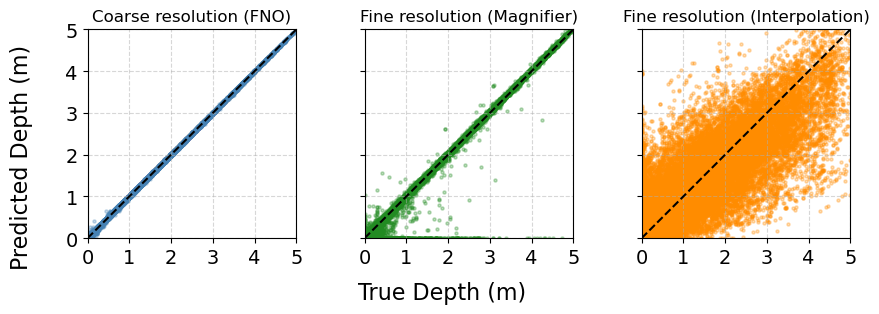

In [26]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ─── Data Setup ─────────────────────────────────────────────────────────────

# Coarse
u_true_c = u_true_all_coarse.detach().cpu().numpy()
u_pred_c = u_pred_coarse_all.detach().cpu().numpy()

# Interpolation baseline (Fine)
u_pred_interp = F.interpolate(
    u_pred_coarse_all.permute(0, 3, 1, 2),   # [B, T, mx, my]
    size=(nx_fine, ny_fine),
    mode='bicubic',
    align_corners=False
).permute(0, 2, 3, 1)                         # [B, H, W, T]
u_pred_interp = torch.clamp(u_pred_interp, min=0.0).detach().cpu().numpy()

# Magnifier (Fine)
u_true_f = u_true_all.detach().cpu().numpy()
u_pred_f = u_upscaled_final.detach().cpu().numpy()

# ─── Helper: Collect Scatter Points ─────────────────────────────────────────

def collect_scatter(u_true, u_pred, max_points_per_sample=5000):
    xs, ys = [], []
    for i in range(u_true.shape[0]):
        x = u_true[i].ravel()
        y = u_pred[i].ravel()

        if x.size > max_points_per_sample:
            idx = np.random.choice(x.size, max_points_per_sample, replace=False)
            x = x[idx]
            y = y[idx]

        xs.append(x)
        ys.append(y)

    return np.concatenate(xs), np.concatenate(ys)

# Build scatter sets
x_c, y_c = collect_scatter(u_true_c, u_pred_c)
x_i, y_i = collect_scatter(u_true_f, u_pred_interp)
x_m, y_m = collect_scatter(u_true_f, u_pred_f)

# Shared limits (use fine domain, since it contains the full range)
limit = 5 #max(x_m.max(), y_m.max(), x_i.max(), y_i.max(), x_c.max(), y_c.max())

# ─── Plot: 1 row × 3 cols ───────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharex=True, sharey=True)

panels = [
    (axes[0], x_c, y_c, "Coarse resolution (FNO)", "steelblue"),
    (axes[1], x_m, y_m, "Fine resolution (Magnifier)", "forestgreen"),
    (axes[2], x_i, y_i, "Fine resolution (Interpolation)", "darkorange"),

]


num_ticks = 6  # change if you want more/less ticks
ticks = np.linspace(0, limit, num_ticks)


for ax, x, y, title, color in panels:
    ax.scatter(x, y, s=5, alpha=0.3, color=color, rasterized=True)
    ax.plot([0, limit], [0, limit], 'k--', lw=1.5)
    ax.set_title(title)

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)

    ax.set_xticks(ticks)
    ax.set_yticks(ticks)


    ax.set_aspect('equal', 'box')
    
    # Make y-axis use the same tick locator as x-axis
    ax.yaxis.set_major_locator(ax.xaxis.get_major_locator())

    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='both', labelsize=14)

# Shared labels
fig.supxlabel("True Depth (m)", fontsize=16)
fig.supylabel("Predicted Depth (m)", fontsize=16)

plt.tight_layout()
plt.savefig('../../../paper/figs/scatter_error_flooding.png', dpi=600, bbox_inches='tight')

plt.show()


In [27]:
metrics_fine_inter = evaluate_flood_metrics(
    Depth_True=u_true_all,
    Depth_Pred=torch.Tensor(u_pred_interp),
    wet_threshold=0.025,
    peak_percent=0.025
)

metrics_fine_inter['static']

{'relRMSE_mean': 1.3875199556350708,
 'relRMSE_std': 0.05224571004509926,
 'NSE_mean': 0.8257262706756592,
 'NSE_std': 0.0071837808936834335,
 'relRMSE_shallow_mean': 9.987390518188477,
 'relRMSE_shallow_std': 0.1748065948486328,
 'NSE_shallow_mean': -3.994137763977051,
 'NSE_shallow_std': 0.09481319040060043,
 'relRMSE_deep_mean': 0.39882752299308777,
 'relRMSE_deep_std': 0.007107541896402836,
 'NSE_deep_mean': 0.5421062707901001,
 'NSE_deep_std': 0.022916464135050774,
 'POD_mean': 0.9644811749458313,
 'POD_std': 0.0018422682769596577,
 'FAR_mean': 0.23053045570850372,
 'FAR_std': 0.008092668838799,
 'CSI_mean': 0.7482482194900513,
 'CSI_std': 0.0069666169583797455,
 'relPeakValErr_mean': 0.014100458472967148,
 'relPeakValErr_std': 0.0020023933611810207,
 'relPeakTimeErr1_mean': 0.0,
 'relPeakTimeErr1_std': 0.4040610194206238,
 'relPeakTimeErr2_mean': -0.0005303669022396207,
 'relPeakTimeErr2_std': 0.028927462175488472}

In [18]:
metrics_fine_inter = evaluate_flood_metrics(
    Depth_True=u_true_all,
    Depth_Pred=torch.Tensor(u_pred_interp),
    wet_threshold=0.025,
    peak_percent=0.025
)

metrics_fine_inter['static']

{'relRMSE_mean': 1.3871116638183594,
 'relRMSE_std': 0.052212223410606384,
 'NSE_mean': 0.8258289098739624,
 'NSE_std': 0.007175520062446594,
 'relRMSE_shallow_mean': 9.980240821838379,
 'relRMSE_shallow_std': 0.17476031184196472,
 'NSE_shallow_mean': -3.986992120742798,
 'NSE_shallow_std': 0.09483453631401062,
 'relRMSE_deep_mean': 0.39877158403396606,
 'relRMSE_deep_std': 0.0070977541618049145,
 'NSE_deep_mean': 0.5422353744506836,
 'NSE_deep_std': 0.022889964282512665,
 'POD_mean': 0.965996265411377,
 'POD_std': 0.0017710872925817966,
 'FAR_mean': 0.2320145070552826,
 'FAR_std': 0.008154382929205894,
 'CSI_mean': 0.7477535009384155,
 'CSI_std': 0.007069324608892202,
 'relPeakValErr_mean': 0.01402302272617817,
 'relPeakValErr_std': 0.002163291908800602,
 'relPeakTimeErr1_mean': -0.10000000149011612,
 'relPeakTimeErr1_std': 0.4164965748786926,
 'relPeakTimeErr2_mean': -0.00798365380614996,
 'relPeakTimeErr2_std': 0.03079487942159176}

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Ever-inundation confusion (sample=1, th=0.025 m)'}, xlabel='x (km)', ylabel='y (km)'>)

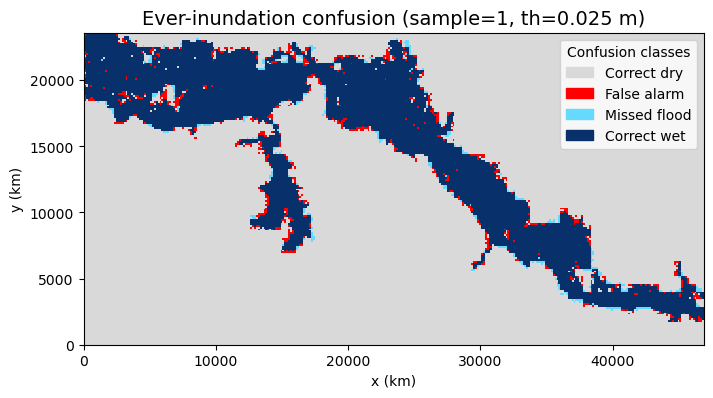

In [28]:
Ly=checkpoint_mag['config_arg']['data_mask']['L_x']
Lx=checkpoint_mag['config_arg']['data_mask']['L_y']
extent = [0, Lx, 0, Ly]


plot_ever_inundation_confusion(u_true_all, u_upscaled_final, sample_idx=1, inund_th=0.025, extent=extent)


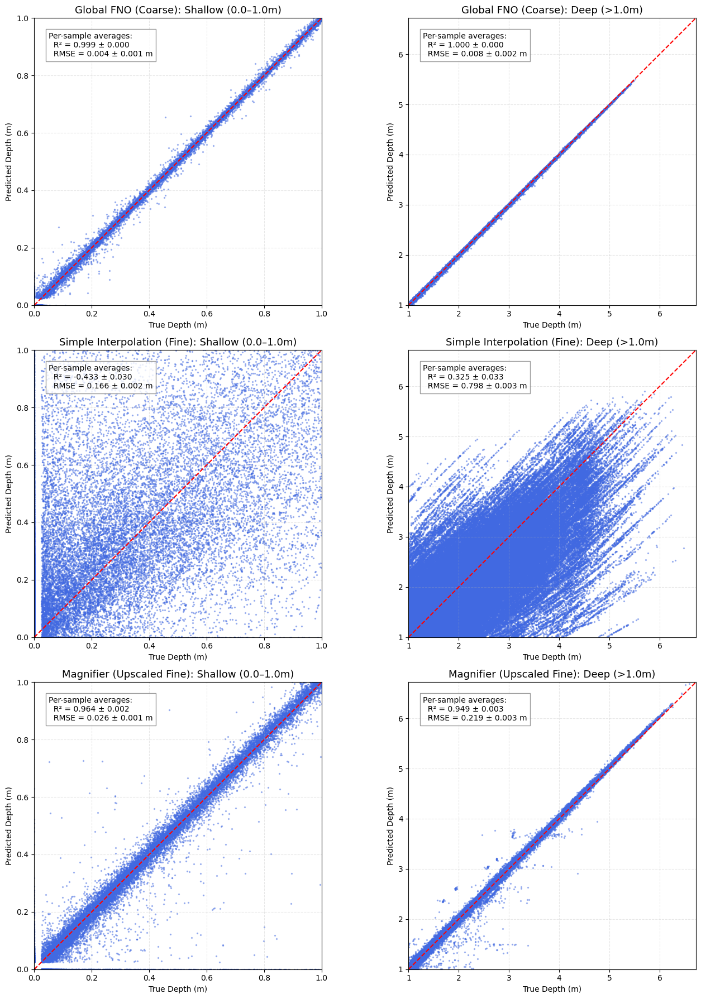

In [29]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# ─── Data Setup ─────────────────────────────────────────────────────────────
# Row 1: Coarse FNO Data
u_true_c = u_true_all_coarse.detach().cpu().numpy()
u_pred_c = u_pred_coarse_all.detach().cpu().numpy()

# Row 2: Simple Interpolation Baseline (Upscaled without Neural Correction)
# We upscale u_pred_coarse_all to [nx_fine, ny_fine] using standard bilinear interpolation
# u_pred_interp = F.interpolate(
#     u_pred_coarse_all.permute(0, 3, 1, 2), # [Batch, T, mx, my]
#     size=(nx_fine, ny_fine), 
#     mode='bilinear', 
#     align_corners=False
# ).permute(0, 2, 3, 1).detach().cpu().numpy() # Back to [Batch, H, W, T]

# Updated Row 2: Bicubic Interpolation Baseline (Matching the DCSCN paper)
# 
u_pred_interp = F.interpolate(
    u_pred_coarse_all.permute(0, 3, 1, 2), # [Batch, T, mx, my]
    size=(nx_fine, ny_fine), 
    mode='bicubic', # Standard SR baseline [cite: 37, 107]
    align_corners=False
).permute(0, 2, 3, 1)

# Critical step: Interpolation can create artifacts or negative depths
u_pred_interp = torch.clamp(u_pred_interp, min=0.0).detach().cpu().numpy()

# Row 3: Magnifier (Neural Upscaling)
u_true_f = u_true_all.detach().cpu().numpy()
u_pred_f = u_upscaled_final.detach().cpu().numpy()

# Note: Both Interpolation and Magnifier are compared against the Fine Ground Truth (u_true_f)
datasets = [
    (u_true_c, u_pred_c, "Global FNO (Coarse)"),
    (u_true_f, u_pred_interp, "Simple Interpolation (Fine)"),
    (u_true_f, u_pred_f, "Magnifier (Upscaled Fine)")
]

# Define depth ranges (m)
depth_ranges = [
    (0.0, 1.0, "Shallow (0.0–1.0m)"),
    (1.0, max(u_true_f.max(), u_pred_f.max()), "Deep (>1.0m)")
]

# 3 rows x 2 cols
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for row_idx, (u_true, u_pred, model_name) in enumerate(datasets):
    for col_idx, (dmin, dmax, range_title) in enumerate(depth_ranges):
        ax = axes[row_idx, col_idx]
        
        r2_list, rmse_list = [], []
        scatter_x, scatter_y = [], []
        
        for i in range(u_true.shape[0]):
            true_flat = u_true[i].ravel()
            pred_flat = u_pred[i].ravel()
            
            mask = (true_flat >= dmin) & (true_flat < dmax)
            if np.sum(mask) < 50: continue
                
            x_s, y_s = true_flat[mask], pred_flat[mask]
            
            r2_list.append(r2_score(x_s, y_s))
            rmse_list.append(np.sqrt(mean_squared_error(x_s, y_s)))
            
            if len(x_s) > 5000:
                sel = np.random.choice(len(x_s), 5000, replace=False)
                scatter_x.extend(x_s[sel]); scatter_y.extend(y_s[sel])
            else:
                scatter_x.extend(x_s); scatter_y.extend(y_s)
        
        ax.scatter(scatter_x, scatter_y, s=2, alpha=0.4, color='royalblue', rasterized=True)
        limit_max = dmax if np.isfinite(dmax) else max(scatter_x)
        ax.plot([dmin, limit_max], [dmin, limit_max], 'r--', lw=1.5, label='Ideal')
        
        ax.set_xlim(dmin, limit_max); ax.set_ylim(dmin, limit_max)
        ax.set_aspect('equal')
        
        metrics_text = (
            f"Per-sample averages:\n"
            f"  R² = {np.mean(r2_list):.3f} ± {np.std(r2_list):.3f}\n"
            f"  RMSE = {np.mean(rmse_list):.3f} ± {np.std(rmse_list):.3f} m"
        )
        ax.text(0.05, 0.95, metrics_text, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))
        
        ax.set_title(f"{model_name}: {range_title}", fontsize=13)
        ax.set_xlabel("True Depth (m)"); ax.set_ylabel("Predicted Depth (m)")
        ax.grid(True, ls='--', alpha=0.3)

plt.tight_layout()
plt.show()

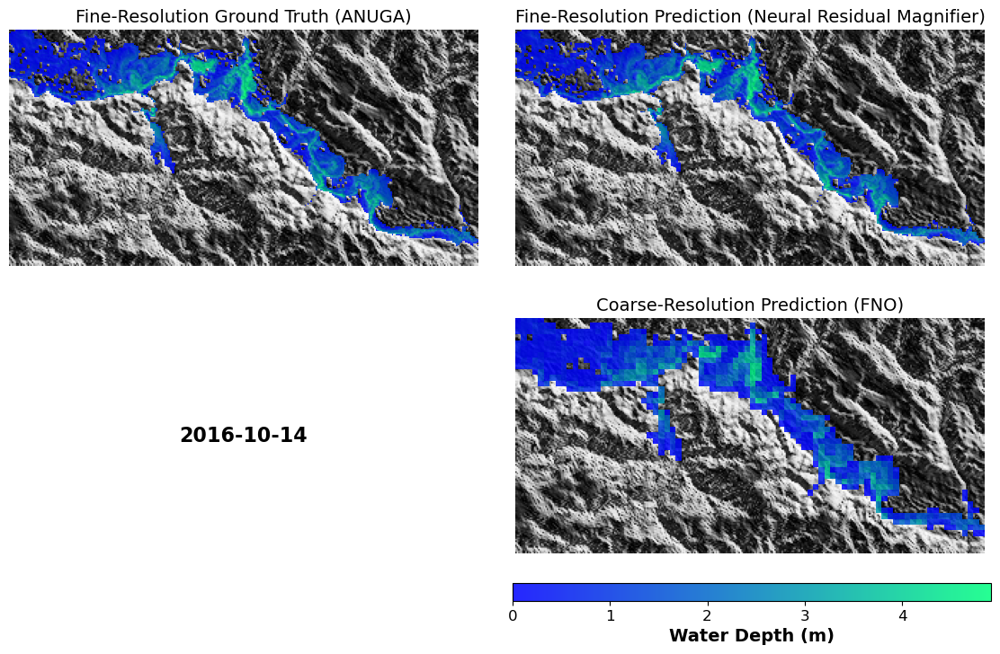

Time: 2016-10-14 08:24  |  Frame: 70/87


In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from datetime import datetime, timedelta

# ---------------------------
# USER CHOICES
# ---------------------------
sample_idx = 20
time_step  = 70  # <-- frame index you want (0 ... num_frames-1)
extent = [0, 46890.0/1000, 0, 23600.0/1000]
# ---------------------------
# DATE RANGE (exact)
# ---------------------------
start_date = datetime(2016, 10, 5, 12, 0, 0)
end_date   = datetime(2016, 10, 16, 12, 0, 0)

# ==========================================
# 4) Hillshade bed background
# ==========================================
bed_sample = bed_topo_all[sample_idx].detach().cpu().numpy()

# ensure bed_sample is [nx, ny] before plotting .T (same convention as water)
if bed_sample.shape[0] != u_true_c.shape[0] and bed_sample.shape[1] == u_true_c.shape[0]:
    bed_sample = bed_sample.T

# ==========================================
# Data (with same stride as your animation)
# ==========================================
u_true_c = u_true_all_coarse[sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[sample_idx].detach().cpu().numpy()

u_true_f = u_true_all[sample_idx].detach().cpu().numpy()
u_pred_f = u_upscaled_final[sample_idx].detach().cpu().numpy()

num_frames = u_true_f.shape[-1]

# build time_dates so first frame=start and last frame=end
total_seconds = (end_date - start_date).total_seconds()
time_step_seconds = total_seconds / (num_frames - 1)
time_dates = [start_date + timedelta(seconds=i * time_step_seconds) for i in range(num_frames)]

# clamp time_step to valid range
time_step = int(np.clip(time_step, 0, num_frames - 1))
current_dt = time_dates[time_step]

# --- Match your reference styling ---
min_depth_threshold = 0.025
cmp = "winter"
bed_cmap = "gist_yarg"

global_max_depth = 0.8 * max(u_true_f.max(), u_pred_f.max())
vmin, vmax = 0.0, global_max_depth

def mask_dry(depth2d, thresh=min_depth_threshold):
    return np.ma.masked_where(depth2d < thresh, depth2d)

# ==========================================
# Hillshade
# ==========================================
Z = bed_sample
dx = 1.0
dy = 1.0
ls = LightSource(azdeg=315, altdeg=45)
hill = ls.hillshade(Z, vert_exag=2.5, dx=dx, dy=dy)

# ==========================================
# Static Figure: 2 Rows x 2 Cols (no error)
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)

# titles = [
#     ["True (Coarse)", "Pred (Coarse)"],
#     ["True (Fine)",   "Pred (Upscaled)"]
# ]
titles = [
    ["True (Fine)",   "Pred (Upscaled)"],
    ["",              "Pred (Coarse)"]
]

# ---- Row 1: coarse ----
coarse_true = u_true_c[:, :, time_step]
coarse_pred = u_pred_c[:, :, time_step]

# ---- Row 2: fine ----
fine_true = u_true_f[:, :, time_step]
fine_pred = u_pred_f[:, :, time_step]


data_grid = [
    [fine_true,   fine_pred],    # Row 1: fine
    [None,        coarse_pred]   # Row 2: coarse (no true coarse)
]
titles = [
    ["Fine-Resolution Ground Truth (ANUGA)", 
     "Fine-Resolution Prediction (Neural Residual Magnifier)"],
    [None, 
     "Coarse-Resolution Prediction (FNO)"]
]

ims = []
for r in range(2):
    for c in range(2):
        ax = axes[r, c]

        # ---- Completely blank panel (Coarse True) ----
        if r == 1 and c == 0:
            ax.set_axis_off()
            ax.text(0.5, 0.5, current_dt.strftime('%Y-%m-%d'),
                    transform=ax.transAxes, ha='center', va='center',
                    fontsize=16, fontweight='bold', color='black')
            continue


        # Bed background
        ax.imshow(
            hill.T, extent=extent, origin="lower",
            cmap=bed_cmap, vmin=0, vmax=1,
            alpha=1.0, zorder=1
        )

        # Water overlay
        im = ax.imshow(
            mask_dry(data_grid[r][c]).T, extent=extent, origin="lower",
            cmap=cmp, vmin=vmin, vmax=vmax,
            alpha=0.85, zorder=2,
            interpolation=("nearest" if r == 1 else None)
        )
        ims.append(im)

        ax.set_title(titles[r][c], fontsize=14)
        ax.set_axis_off()


# --- Horizontal colorbar at bottom ---
cbar_ax = fig.add_axes([0.525, 0.08, 0.38, 0.025])  # [left, bottom, width, height]
cbar = fig.colorbar(ims[-1], cax=cbar_ax, orientation="horizontal")

cbar.set_label("Water Depth (m)", fontsize=14, fontweight='bold')
cbar.ax.tick_params(labelsize=12)

plt.subplots_adjust(bottom=0.14, hspace=0.18, wspace=0.08)
plt.savefig(f"../../../paper/figs/2d_depth_{current_dt.strftime('%Y_%m_%d')}.png",
            dpi=600, bbox_inches='tight')
plt.show()

print(f"Time: {current_dt.strftime('%Y-%m-%d %H:%M')}  |  Frame: {time_step}/{num_frames-1}")

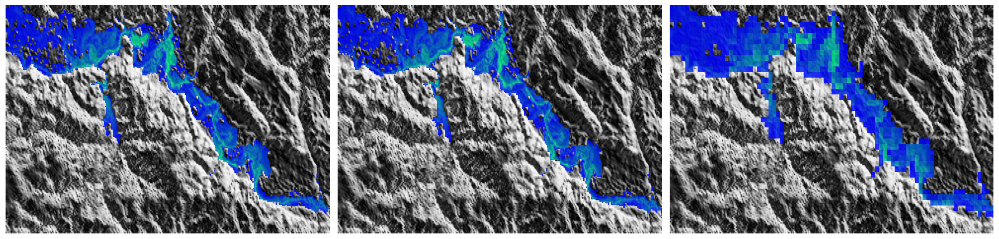

Time: 2016-10-16 12:00  |  Frame: 87/87


In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from datetime import datetime, timedelta

# ---------------------------
# USER CHOICES
# ---------------------------
sample_idx = 20
time_step  = 87  # <-- frame index you want (0 ... num_frames-1)
extent = [0, 46890.0/1000, 0, 23600.0/1000]
# ---------------------------
# DATE RANGE (exact)
# ---------------------------
start_date = datetime(2016, 10, 5, 12, 0, 0)
end_date   = datetime(2016, 10, 16, 12, 0, 0)

# ==========================================
# 4) Hillshade bed background
# ==========================================
bed_sample = bed_topo_all[sample_idx].detach().cpu().numpy()

# ensure bed_sample is [nx, ny] before plotting .T (same convention as water)
if bed_sample.shape[0] != u_true_c.shape[0] and bed_sample.shape[1] == u_true_c.shape[0]:
    bed_sample = bed_sample.T

# ==========================================
# Data (with same stride as your animation)
# ==========================================
u_true_c = u_true_all_coarse[sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[sample_idx].detach().cpu().numpy()

u_true_f = u_true_all[sample_idx].detach().cpu().numpy()
u_pred_f = u_upscaled_final[sample_idx].detach().cpu().numpy()

num_frames = u_true_f.shape[-1]

# build time_dates so first frame=start and last frame=end
total_seconds = (end_date - start_date).total_seconds()
time_step_seconds = total_seconds / (num_frames - 1)
time_dates = [start_date + timedelta(seconds=i * time_step_seconds) for i in range(num_frames)]

# clamp time_step to valid range
time_step = int(np.clip(time_step, 0, num_frames - 1))
current_dt = time_dates[time_step]

# --- Match your reference styling ---
min_depth_threshold = 0.025
cmp = "winter"
bed_cmap = "gist_yarg"

global_max_depth = 0.8 * max(u_true_f.max(), u_pred_f.max())
vmin, vmax = 0.0, global_max_depth

def mask_dry(depth2d, thresh=min_depth_threshold):
    return np.ma.masked_where(depth2d < thresh, depth2d)

# ==========================================
# Hillshade
# ==========================================
Z = bed_sample
dx = 1.0
dy = 1.0
ls = LightSource(azdeg=315, altdeg=45)
hill = ls.hillshade(Z, vert_exag=2.5, dx=dx, dy=dy)

# ==========================================
# Static Figure: 2 Rows x 2 Cols (no error)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)


# titles = [
#     ["True (Coarse)", "Pred (Coarse)"],
#     ["True (Fine)",   "Pred (Upscaled)"]
# ]
titles = [
    ["True (Fine)",   "Pred (Upscaled)"],
    ["",              "Pred (Coarse)"]
]

# ---- Row 1: coarse ----
coarse_true = u_true_c[:, :, time_step]
coarse_pred = u_pred_c[:, :, time_step]

# ---- Row 2: fine ----
fine_true = u_true_f[:, :, time_step]
fine_pred = u_pred_f[:, :, time_step]

# data_grid = [
#     [coarse_true, coarse_pred],
#     [fine_true,   fine_pred]
# ]


data_grid = [
    [fine_true,   fine_pred],    # Row 1: fine
    [None,        coarse_pred]   # Row 2: coarse (no true coarse)
]
titles = [
    ["Fine-Resolution Ground Truth (ANUGA)", 
     "Fine-Resolution Prediction (Neural Residual Magnifier)"],
    [None, 
     "Coarse-Resolution Prediction (FNO)"]
]

ims = []
for c in range(3):
    ax = axes[c]

    # panel mapping: 0=True fine, 1=pred fine, 2=pred coarse
    if c == 0:
        panel = fine_true
        title = f"Fine-Resolution\nGround Truth (ANUGA)"
        interp = None
    elif c == 1:
        panel = fine_pred
        title = f"Fine-Resolution Prediction\n(Neural Residual Magnifier)"
        interp = None
    else:
        panel = coarse_pred
        title = "Coarse-Resolution\nPrediction (FNO)"
        interp = "nearest"

    # Bed background
    ax.imshow(
        hill.T, extent=extent, origin="lower",
        cmap=bed_cmap, vmin=0, vmax=1,
        alpha=1.0, zorder=1
    )

    # Water overlay
    im = ax.imshow(
        mask_dry(panel).T, extent=extent, origin="lower",
        cmap=cmp, vmin=vmin, vmax=vmax,
        alpha=0.85, zorder=2,
        interpolation=interp
    )
    ims.append(im)

    # ax.set_title(title, fontsize=16)
    ax.set_axis_off()
    ax.set_aspect(1.4)



plt.subplots_adjust(bottom=0.14, hspace=0.18, wspace=0.08)
plt.savefig(f"../../../paper/figs/2d_depth_{current_dt.strftime('%Y_%m_%d')}_V.png",
            dpi=600, bbox_inches='tight')
plt.tight_layout()

plt.show()

print(f"Time: {current_dt.strftime('%Y-%m-%d %H:%M')}  |  Frame: {time_step}/{num_frames-1}")

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import LightSource
from IPython.display import HTML
from datetime import datetime, timedelta


# ==========================================
# 1) Data Selection & Error Calculation
# ==========================================

sample_idx = 20 

# ==========================================
# 2) Coordinate & Color Configuration
# ==========================================
start_date = datetime(2016, 10, 5, 12, 0, 0)
end_date   = datetime(2016, 10, 16, 12, 0, 0)


# ==========================================
# 4) Hillshade bed background (same as first row script)
# ==========================================
# Use your bed tensor here (NOT water). Example: bed_topo_all
bed_sample = bed_topo_all[sample_idx].detach().cpu().numpy()

# ensure bed_sample is [nx, ny] before plotting .T (same convention as water)
# if bed is [ny, nx], transpose it once here
if bed_sample.shape[0] != u_true_c.shape[0] and bed_sample.shape[1] == u_true_c.shape[0]:
    bed_sample = bed_sample.T

# Row 1: Coarse Data [nx_c, ny_c, nt]
u_true_c = u_true_all_coarse[..., ::4][sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[..., ::4][sample_idx].detach().cpu().numpy()
u_err_c  = np.abs(u_true_c - u_pred_c)

# Row 2: Upscaled Data [nx_f, ny_f, nt]
u_true_f = u_true_all[..., ::4][sample_idx].detach().cpu().numpy() 
u_pred_f = u_upscaled_final[..., ::4][sample_idx].detach().cpu().numpy()
u_err_f  = np.abs(u_true_f - u_pred_f)

num_frames = u_true_f.shape[-1]


total_seconds = (end_date - start_date).total_seconds()
time_step_seconds = total_seconds / (num_frames - 1)

time_dates = [
    start_date + timedelta(seconds=i * time_step_seconds)
    for i in range(num_frames)
]


# --- Match your reference styling ---
min_depth_threshold = 0.025
cmp = "winter"          # water colormap
bed_cmap = "gist_yarg"       # hillshade is already grayscale; keep "gray"

# Choose water scaling like your reference:
global_max_depth = 0.8 * max(u_true_f.max(), u_pred_f.max())
vmin, vmax = 0.0, global_max_depth
err_vmin, err_vmax = 0.0, 0.2

# Helper: mask "dry" pixels so bed shows through
def mask_dry(depth2d, thresh=min_depth_threshold):
    return np.ma.masked_where(depth2d < thresh, depth2d)

# ==========================================
# 0) Build "3D-looking" bed background (hillshade)
# ==========================================
# bed_sample is [nx, ny]
Z = bed_sample

# If you know grid resolution, set dx,dy properly. Otherwise 1.0 is fine visually.
dx = 1.0
dy = 1.0

ls = LightSource(azdeg=315, altdeg=45)     # light direction/elevation (tweakable)
hill = ls.hillshade(Z, vert_exag=2.5, dx=dx, dy=dy)  # vert_exag controls "3D strength"

# hill is in [0,1], shape [nx, ny]
# We'll plot hill.T (like your other layers)

# ==========================================
# Figure Setup: 2 Rows x 3 Columns
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)

titles = [
    ["True (Coarse)", "Pred (Coarse)", "Abs Error (Coarse)"],
    ["True (Fine)",   "Pred (Upscaled)", "Abs Error (Fine)"]
]

ims = [[None for _ in range(3)] for _ in range(2)]
bed_images = []
fine_interp = None
for r in range(2):
    t_d = u_true_c if r == 0 else u_true_f
    p_d = u_pred_c if r == 0 else u_pred_f
    e_d = u_err_c  if r == 0 else u_err_f

    for c in range(3):
        ax = axes[r, c]

        # 1) Hillshade bed background (3D-looking)
        bed_img = ax.imshow(
            hill.T, extent=extent, origin="lower",
            cmap=bed_cmap, vmin=0, vmax=1,
            alpha=1.0, zorder=1
        )
        bed_images.append(bed_img)

        # 2) Foreground layers
        if c == 0:
            frame0 = t_d[:, :, 0]
            ims[r][c] = ax.imshow(
                mask_dry(frame0).T, extent=extent, origin="lower",
                cmap=cmp, vmin=vmin, vmax=vmax,
                alpha=0.85, zorder=2,
                interpolation=(fine_interp if r == 1 else "nearest")
            )
        elif c == 1:
            frame0 = p_d[:, :, 0]
            ims[r][c] = ax.imshow(
                mask_dry(frame0).T, extent=extent, origin="lower",
                cmap=cmp, vmin=vmin, vmax=vmax,
                alpha=0.85, zorder=2,
                interpolation=(fine_interp if r == 1 else "nearest")
            )
        else:
            frame0 = e_d[:, :, 0]
            ims[r][c] = ax.imshow(
                frame0.T, extent=extent, origin="lower",
                cmap="magma", vmin=err_vmin, vmax=err_vmax,
                alpha=0.7, zorder=2
            )

        ax.set_title(titles[r][c], fontsize=12)
        ax.grid(True, linestyle="--", alpha=0.3)

# Colorbars
cbar_ax1 = fig.add_axes([0.15, 0.06, 0.35, 0.02])
fig.colorbar(ims[1][0], cax=cbar_ax1, label="Water Depth (m)", orientation="horizontal")

cbar_ax2 = fig.add_axes([0.65, 0.06, 0.20, 0.02])
fig.colorbar(ims[1][2], cax=cbar_ax2, label="Abs Error (m)", orientation="horizontal")

plt.subplots_adjust(bottom=0.15, hspace=0.2, wspace=0.1)

# ==========================================
# Update Function
# ==========================================
def update(f_idx):
    current_dt = time_dates[f_idx]
    fig.suptitle(
        f"Flood Refinement Analysis: Sample {sample_idx}\nTime: {current_dt.strftime('%Y-%m-%d %H:%M')}",
        fontsize=16, fontweight="bold"
    )

    # Coarse
    t0 = u_true_c[:, :, f_idx]
    p0 = u_pred_c[:, :, f_idx]
    ims[0][0].set_data(mask_dry(t0).T)
    ims[0][1].set_data(mask_dry(p0).T)
    ims[0][2].set_data(u_err_c[:, :, f_idx].T)

    # Fine
    t1 = u_true_f[:, :, f_idx]
    p1 = u_pred_f[:, :, f_idx]
    ims[1][0].set_data(mask_dry(t1).T)
    ims[1][1].set_data(mask_dry(p1).T)
    ims[1][2].set_data(u_err_f[:, :, f_idx].T)

    return [item for sublist in ims for item in sublist]

ani = animation.FuncAnimation(fig, update, frames=range(num_frames), interval=200, blit=False)
plt.close(fig)
HTML(ani.to_jshtml())


Animation size has reached 21619951 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
